## Wiener Filter

In [2]:
import jax
jax.config.update("jax_enable_x64", True)
from jax import numpy as jnp 
import numpy as np

import sys 
sys.path.insert(1, '../')

from shear.planes import cosmo, get_planes, get_source_scales
from shear.wiener import get_Q, measure_power_spectrum, invert_v
from shear.metrics import pearson_cc
from shear.fourier import ks93inv_batch
from shear.photoz import weighted_proj

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

import os 
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

### Define and load variables

In [3]:
pm_seed = 0                     # Particle mesh seed
field_size = 5                  # Size of the lensing field in degrees
field_npix = 75                 # Number of pixels in the lensing field
num_bins = 30                   # Number of light source bins
shape_sigma = 0.035             # Standard deviation of gaussian shape noise
alpha = 1                       # Weight of wiener filter prior

planes_interp = jnp.load('../pm_fields/pm%d.npy'%pm_seed, allow_pickle=True)
z_source = jnp.load('../pm_fields/pm%d_z_source.npy'%pm_seed)

od = get_planes(planes_interp)

### Bin light source locations

In [4]:
z_source = z_source.reshape(64, 75*75)
z_source_bin_id = (z_source * num_bins / 2).astype('int')
avg_gals_per_bin = (np.bincount(z_source_bin_id.flatten()) / (field_npix * field_npix))
bin_locs = jnp.linspace(0.05, 1.95, num=num_bins)

### Calculate projection weights, shear measurements

In [5]:
pws = get_source_scales(cosmo, planes_interp, z_source[..., None]).reshape(64, 75*75, 20, 1)

e1, e2 = ks93inv_batch(od, jnp.zeros((75, 75)))
target = jnp.stack([e1, e2], axis=-1).reshape(-1, 2)
target = jnp.array([weighted_proj(target, pw) for pw in pws])

noise_key = jax.random.PRNGKey(0) #same noise key as nerf
noise = jax.random.normal(noise_key, shape=target.shape) * 0.035

target = target + noise

g1 = target[..., 0]
g2 = target[..., 1]

### Compute lensing efficiency Q, fourier components of noisy shear, noise matrix N

In [6]:
Q, g1hat, g2hat = get_Q(z_source_bin_id, pws, g1, g2)
od = od.transpose(2, 0, 1)[:18]
N = jnp.diag(shape_sigma**2 / avg_gals_per_bin)

### Compute prior matrix S

In [7]:
k1, k2 = jnp.meshgrid(jnp.fft.fftfreq(field_npix), jnp.fft.fftfreq(field_npix))
p1 = k1 * k1 - k2 * k2
p2 = 2 * k1 * k2
k2 = k1 * k1 + k2 * k2
k2 = k2.at[0,0].set(1)

freqs = jnp.fft.fftfreq(field_npix, 1/field_npix)
mi, mj = jnp.meshgrid(freqs, freqs)
r_arr = jnp.sqrt(((mi)**2 + (mj)**2)).astype('int')

ps = jnp.array([measure_power_spectrum(od[i]) for i in tqdm(range(len(od)))])
S = jnp.array([jnp.diag(ps[:, r]) for r in r_arr.flatten()])

  0%|          | 0/18 [00:00<?, ?it/s]

### Run wiener filter inversion

In [8]:
out_E, out_B = invert_v(g1hat.reshape(num_bins, -1), 
                        g2hat.reshape(num_bins, -1),
                        S,
                        p1.reshape(-1, 1),
                        p2.reshape(-1, 1),
                        k2.reshape(-1, 1), 
                        alpha, 
                        Q, 
                        N)

recon_E = jnp.array([jnp.fft.ifft2(out_E[...,i].reshape(field_npix, field_npix)).real for i in range(18)])
ps_recon = jnp.array([measure_power_spectrum(recon_E[i]) for i in tqdm(range(len(recon_E)))])

  0%|          | 0/18 [00:00<?, ?it/s]

### Cross-correlation

In [9]:
print(pearson_cc(recon_E, od))
print(pearson_cc(recon_E[3:14], od[3:14]))

0.38589982259117345
0.4832558274074647


### Save results

In [10]:
jnp.save('../wiener_recon/pm%d_wiener.npy'%pm_seed, recon_E)

### Plot Wiener filter reconstruction

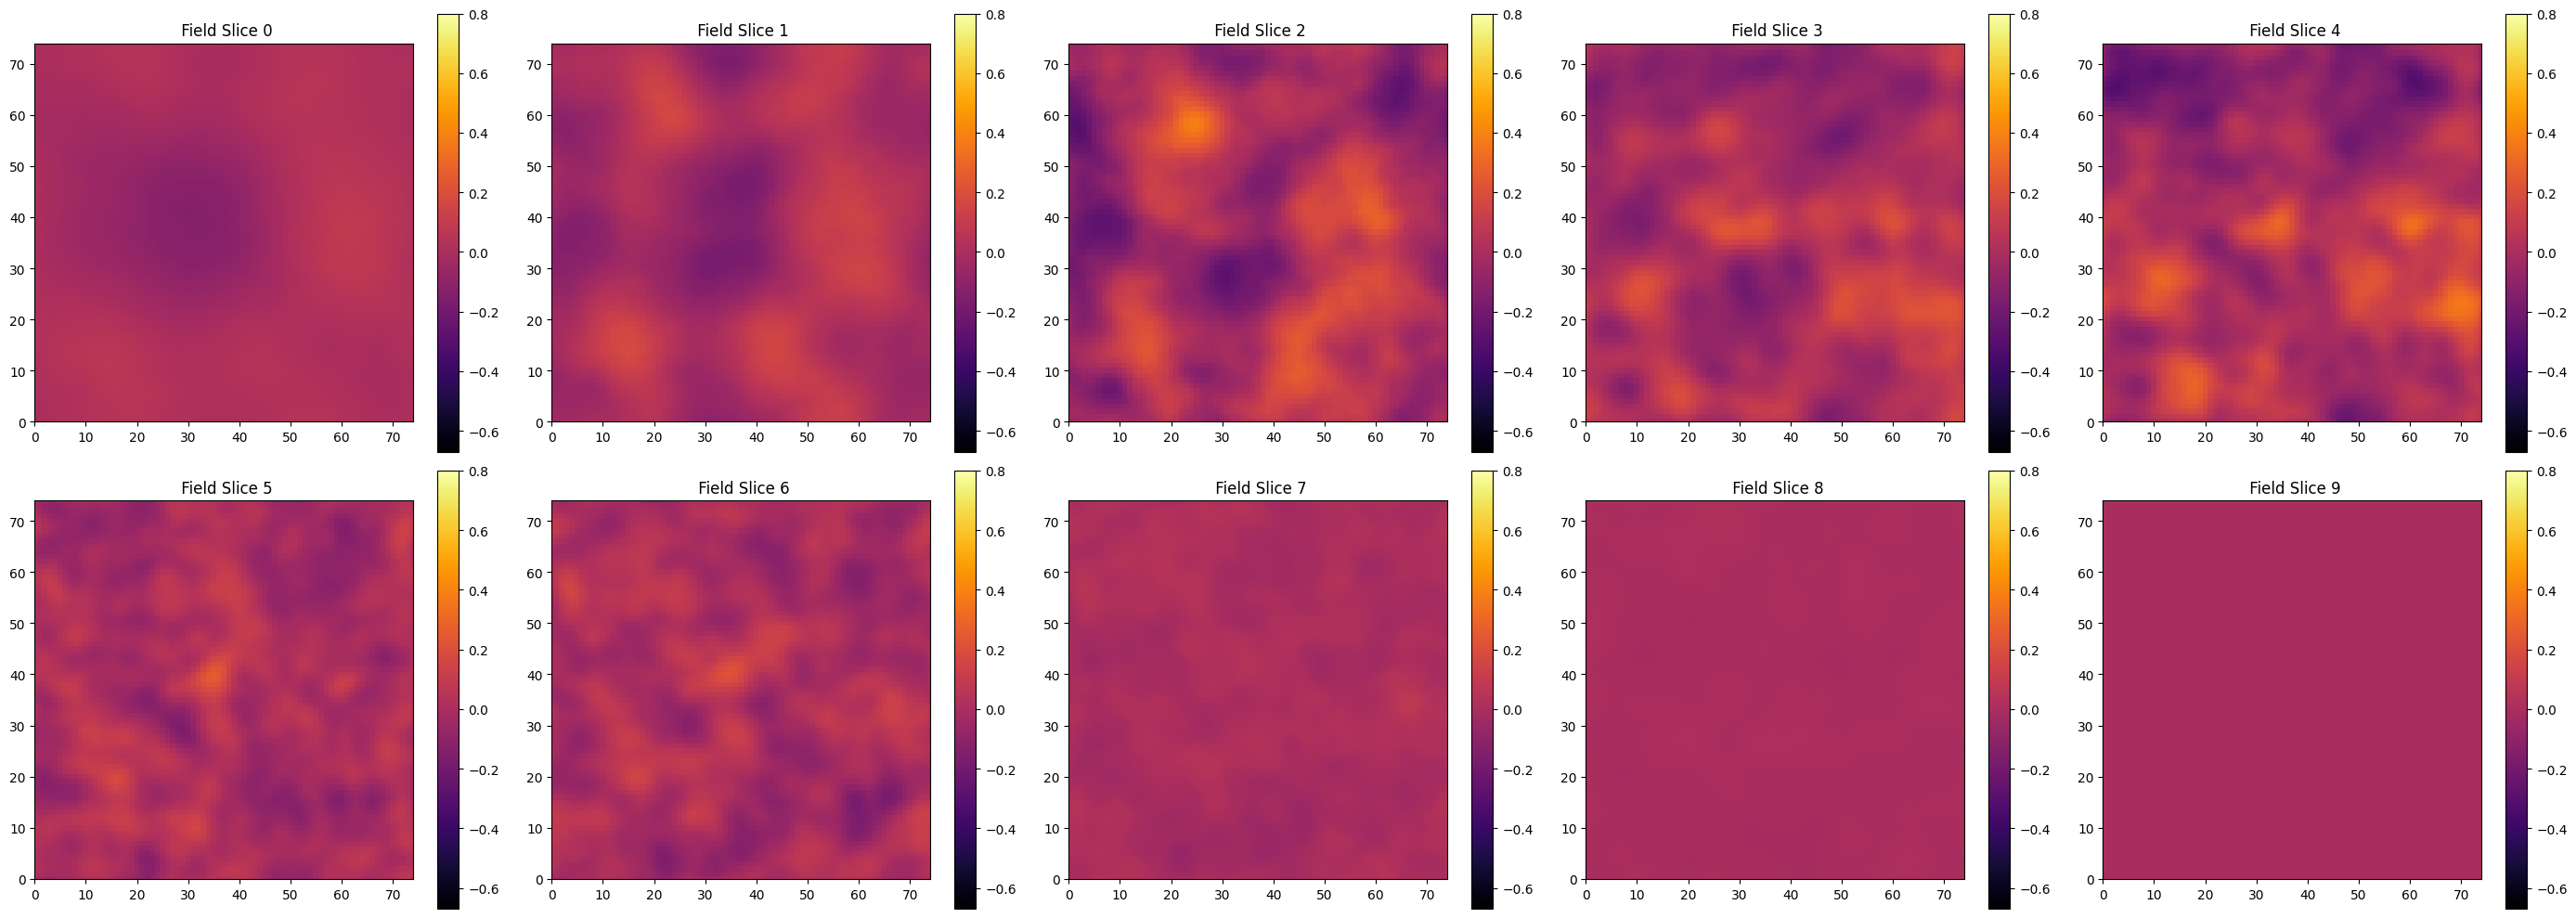

In [11]:
def make_slice_plots_conv(eta_true, res_eta, vmin, vmax, writer, i, title, cmap='inferno'): 
	eta_slice = eta_true.reshape(res_eta, res_eta, 10, -1).mean(3)
	fig, axes = plt.subplots(2, 5, figsize=(28., 10.))
	for j in range(10): 
		k = j % 5
		l = j // 5
		ax = axes[l, k]
		ax.set_xlim([0, res_eta - 1])
		ax.set_ylim([0, res_eta - 1])
		ax.set_title(title+' Field Slice %d'%j)
		heatmap_im = ax.imshow(eta_slice[:, :, j].T, vmin=vmin, vmax=vmax, cmap=cmap)
		plt.colorbar(heatmap_im, ax=ax)
	fig.tight_layout()
	if writer is not None:
		writer.add_figure(title+' Slice Plot', fig, i)
	else: 
		plt.show()
	plt.close()

recon_E_pad = jnp.concatenate([recon_E, np.zeros((2, 75, 75))], axis=0)
make_slice_plots_conv(recon_E_pad.transpose((1,2,0)), 75, -0.67, 0.8, None, 0, '')

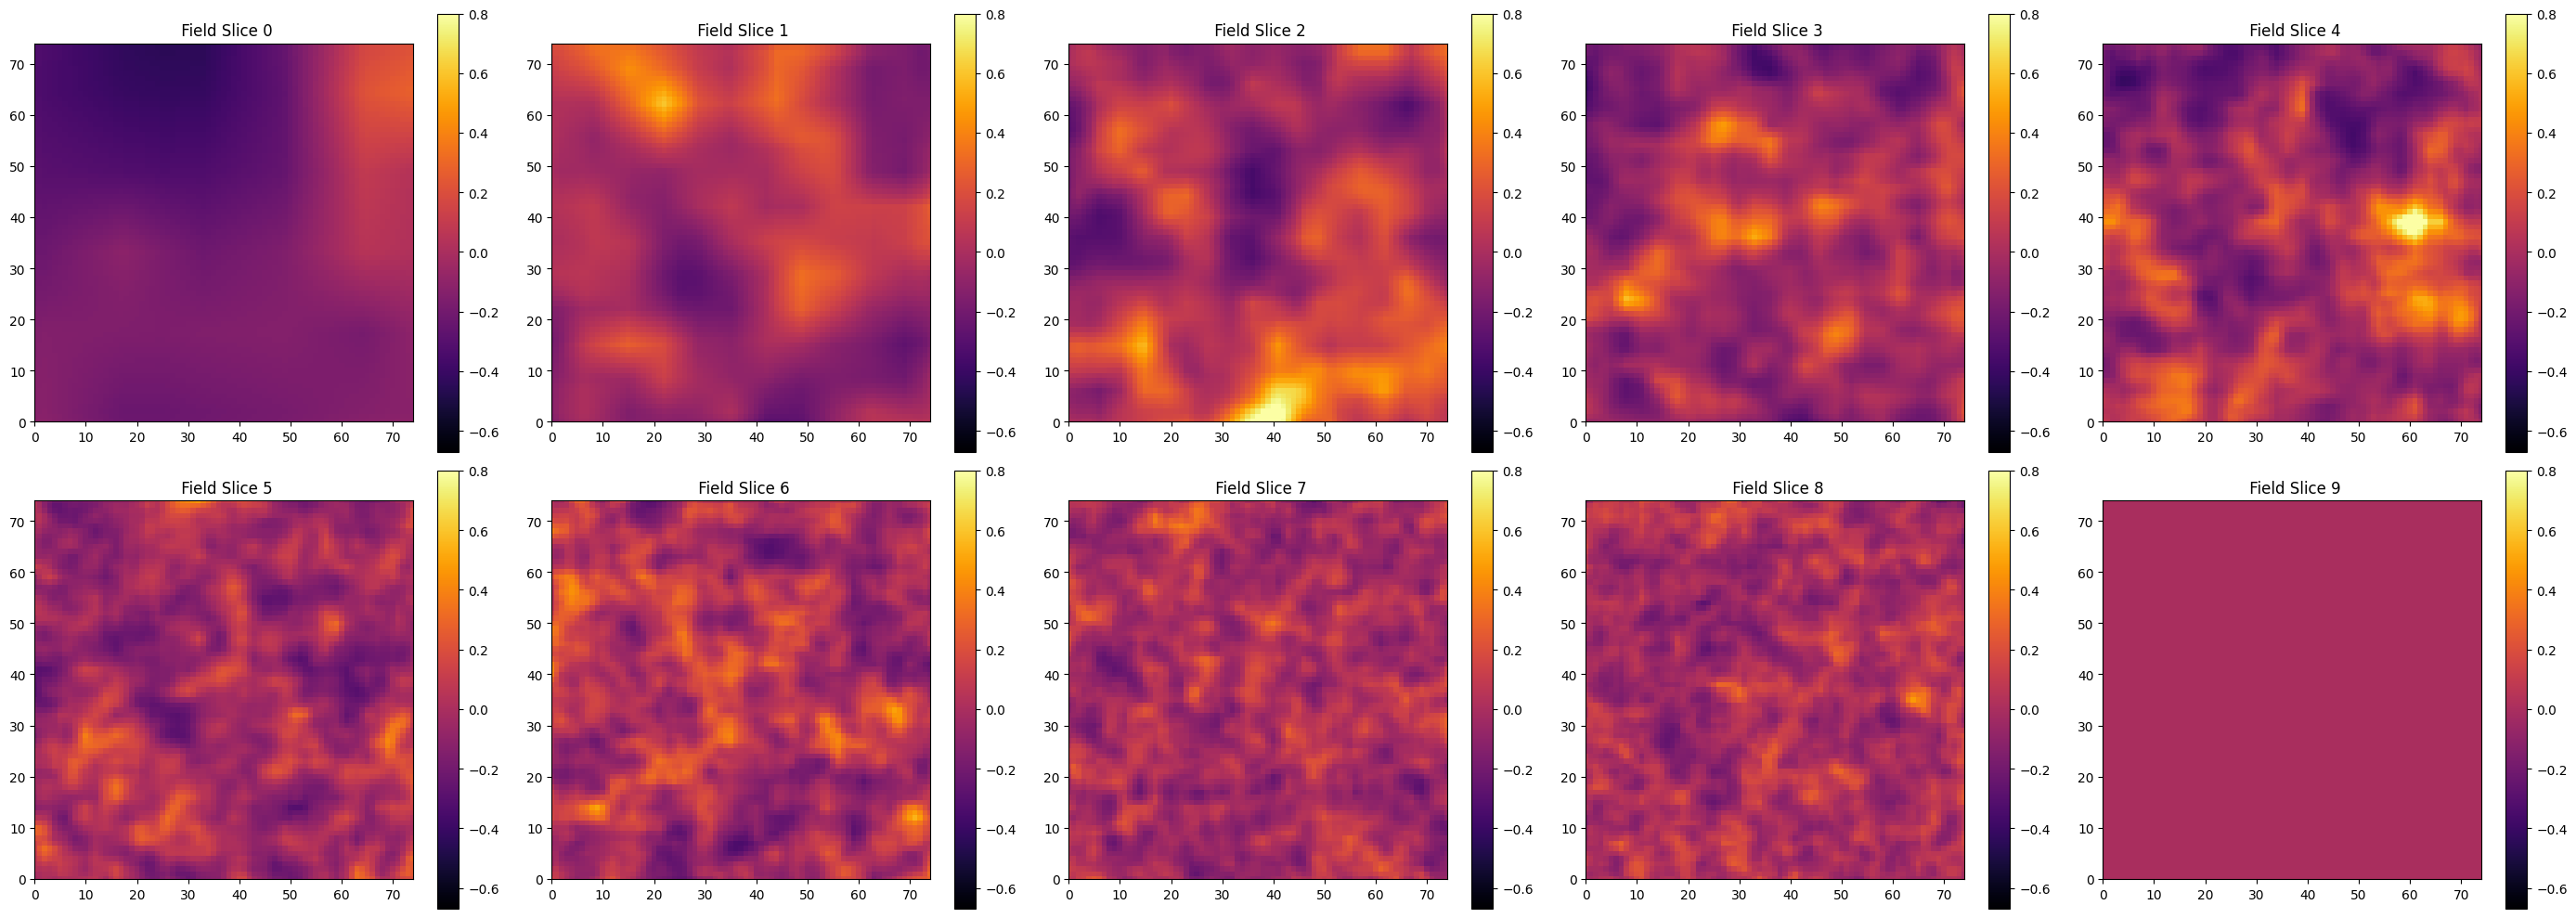

In [13]:
make_slice_plots_conv(jnp.concatenate([od, np.zeros((2, 75, 75))], axis=0).transpose((1,2,0)), 75, -0.67, 0.8, None, 0, '')